# 音乐数据可视化

本 notebook 对 `data/` 目录下的四份 CSV 做简单的可视化展示：

- `full_music_data.csv`：逐首歌的音频特征
- `data_by_artist.csv`：按艺术家聚合
- `data_by_year.csv`：按年份聚合
- `influence_data.csv`：音乐人影响关系网络

运行前请确认已安装 `pandas`、`matplotlib`、`seaborn`。

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_style('whitegrid')
plt.rcParams['figure.dpi'] = 100

DATA = 'data'

music = pd.read_csv(f'{DATA}/full_music_data.csv')
by_artist = pd.read_csv(f'{DATA}/data_by_artist.csv')
by_year = pd.read_csv(f'{DATA}/data_by_year.csv')
influence = pd.read_csv(f'{DATA}/influence_data.csv')

print('full_music_data:', music.shape)
print('data_by_artist:', by_artist.shape)
print('data_by_year:', by_year.shape)
print('influence_data:', influence.shape)

full_music_data: (98340, 19)
data_by_artist: (5854, 16)
data_by_year: (100, 14)
influence_data: (42770, 8)


## 1. 歌曲年代分布

按十年统计歌曲数量。

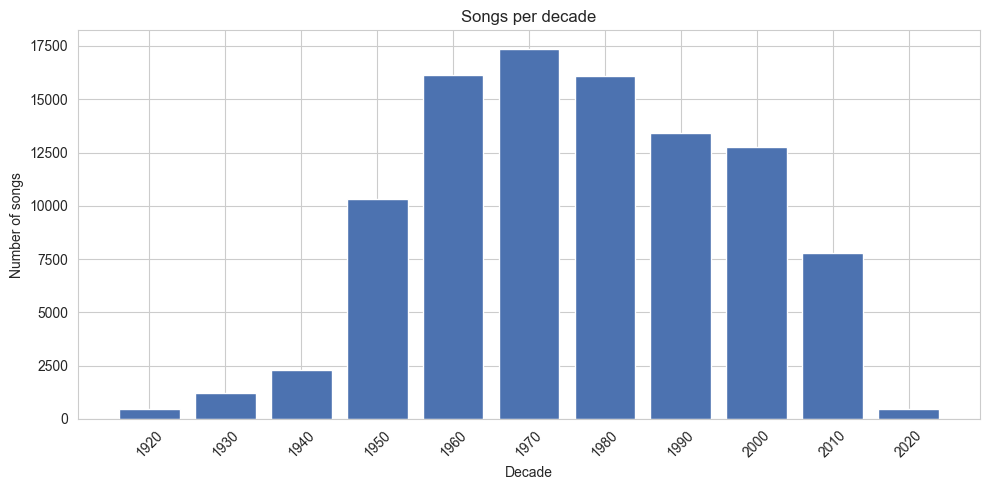

In [2]:
music['year'] = pd.to_numeric(music['year'], errors='coerce')
decade = (music['year'] // 10 * 10).astype('Int64')
counts = decade.value_counts().sort_index()

plt.figure(figsize=(10, 5))
plt.bar(counts.index.astype(str), counts.values, color='#4C72B0')
plt.xlabel('Decade')
plt.ylabel('Number of songs')
plt.title('Songs per decade')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

## 2. 音频特征随年代演变

基于按年份聚合的均值，看 danceability / energy / valence / acousticness 如何随时间变化。

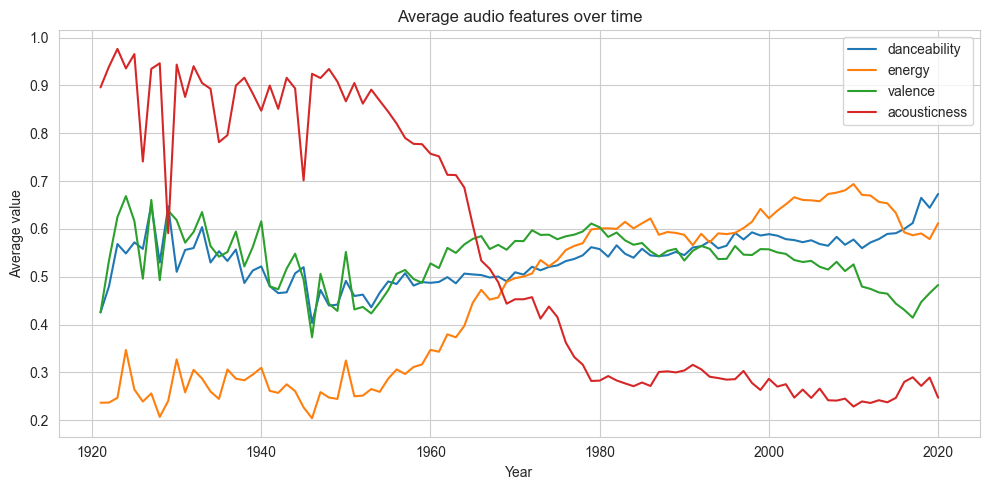

In [3]:
by_year['year'] = pd.to_numeric(by_year['year'])
features = ['danceability', 'energy', 'valence', 'acousticness']

plt.figure(figsize=(10, 5))
for f in features:
    plt.plot(by_year['year'], by_year[f], label=f)
plt.xlabel('Year')
plt.ylabel('Average value')
plt.title('Average audio features over time')
plt.legend()
plt.tight_layout()
plt.show()

## 3. 影响网络流派分布

统计影响者中最主流的流派（按影响边数量）。

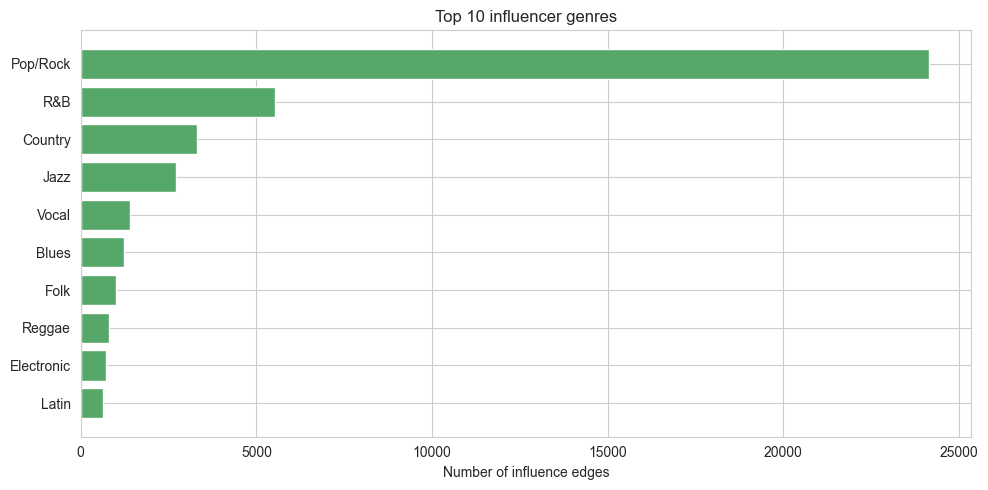

In [4]:
inf_genre = influence['influencer_main_genre'].str.replace(';', '', regex=False)
top = inf_genre.value_counts().head(10)

plt.figure(figsize=(10, 5))
plt.barh(top.index[::-1], top.values[::-1], color='#55A868')
plt.xlabel('Number of influence edges')
plt.title('Top 10 influencer genres')
plt.tight_layout()
plt.show()

## 4. 音频特征相关性

各音频特征（及流行度）之间的相关系数热力图。

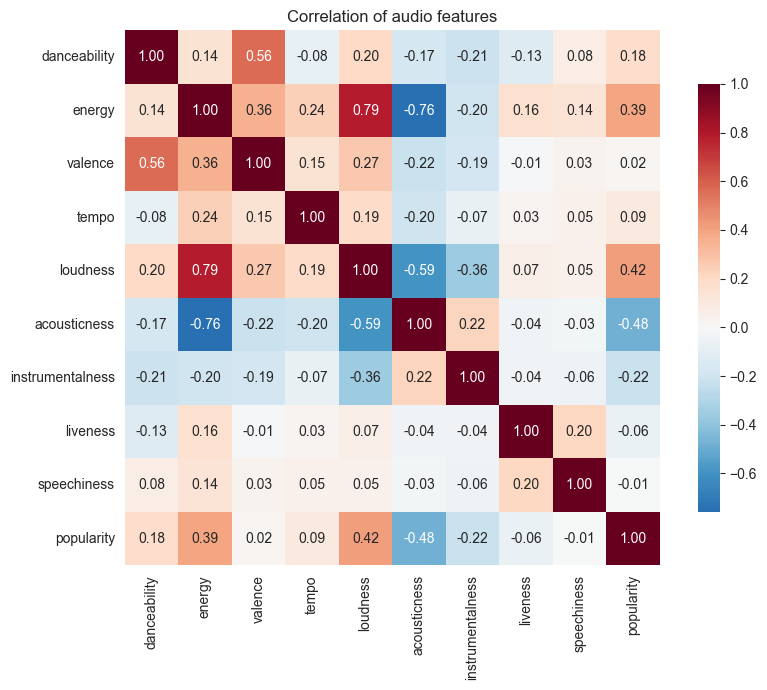

In [5]:
audio_cols = ['danceability', 'energy', 'valence', 'tempo', 'loudness',
              'acousticness', 'instrumentalness', 'liveness', 'speechiness',
              'popularity']
corr = music[audio_cols].corr()

plt.figure(figsize=(9, 7))
sns.heatmap(corr, annot=True, fmt='.2f', cmap='RdBu_r', center=0,
            square=True, cbar_kws={'shrink': 0.8})
plt.title('Correlation of audio features')
plt.tight_layout()
plt.show()

## 5. 流行度分布

歌曲流行度（0–100）的直方图。

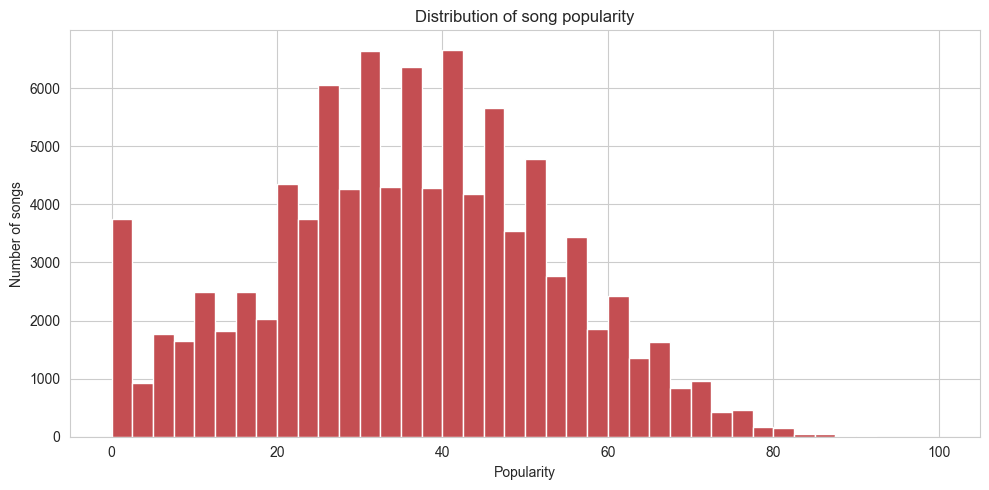

In [6]:
plt.figure(figsize=(10, 5))
plt.hist(music['popularity'], bins=40, color='#C44E52')
plt.xlabel('Popularity')
plt.ylabel('Number of songs')
plt.title('Distribution of song popularity')
plt.tight_layout()
plt.show()